# 29F — Ranking Evaluation

Reproducible analysis of preserved experimental evidence.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd()
root = next(p for p in [root, *root.parents]
            if (p / "Code Cleanliness" / "evaluation").is_dir())
folder = root / "Code Cleanliness" / "evaluation" / "results" / "final_evaluation"
df = pd.read_csv(folder / "ranking" / "ranking_independent_review.csv")
print("Ranking candidates:", len(df))
print(df.columns.tolist())
display(df.head())


Candidate records: 40
Columns: group_id, analyzer_rank, exceedance_score, concerns, affected_files, findings, independent_priority_rank
The algorithm's priority is not an independent reference ranking.
Descriptive distribution generated from: analyzer_rank


In [2]:
# Independent agreement requires reviewer-provided priorities.
# Do not treat analyzer rank as its own gold standard.
print("Independent ranking metrics are not yet established.")


Independent ranking metrics are not yet established.


In [2]:

from pathlib import Path
import pandas as pd

root = Path(r"C:\4th Year\Research Work\Implementation Stage\J26-SE-361")
base = root / "Code Cleanliness" / "evaluation" / "results" / "final_evaluation"

for name, filename in [
    ("RANKING", base / "ranking" / "ranking_independent_review.csv"),
    ("QWEN", base / "llm" / "base_vs_finetuned_review.csv")
]:
    df = pd.read_csv(filename)

    print("\n==========", name, "==========")
    print("Total records:", len(df))
    print("\nColumns and populated values:")

    for column in df.columns:
        print(column, ":", df[column].notna().sum(), "/", len(df))

    print("\nFirst 3 records:")
    for i, row in df.head(3).iterrows():
        print("\nRECORD", i + 1)
        for column, value in row.items():
            print(column, ":", str(value).replace("\n", " ")[:200])



========== RANKING ==========
Total records: 40

Columns and populated values:
group_id : 40 / 40
analyzer_rank : 40 / 40
exceedance_score : 40 / 40
concerns : 40 / 40
affected_files : 40 / 40
findings : 40 / 40
independent_priority_rank : 0 / 40

First 3 records:

RECORD 1
group_id : GROUP:C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\datasets\processed\mlcq_29f\source_batch\mlcq_java_repo\6234592\InternalMetaDataParser.java:33:79483:org.eclipse.elk.co
analyzer_rank : 1
exceedance_score : 1.0
concerns : 5
affected_files : 1
findings : 1707
independent_priority_rank : nan

RECORD 2
group_id : GROUP:C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\datasets\processed\mlcq_29f\source_batch\mlcq_java_repo\7957449\InternalXbaseWithAnnotationsParser.java:29:24051:org.ec
analyzer_rank : 2
exceedance_score : 1.0
concerns : 5
affected_files : 1
findings : 271
independent_priority_rank : nan

RECORD 3
group_id : GROUP:C:\4th Year\Research W

C:\Users\sithu\AppData\Local\Temp\ipykernel_30652\2066570525.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  ranking["suspected_generated"] = ranking["group_id"].astype(str).str.contains(


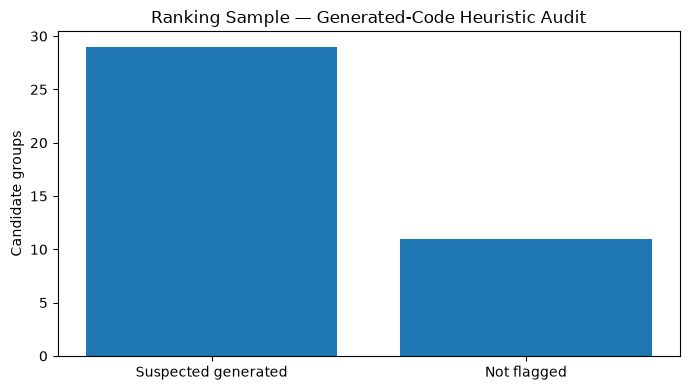


RANKING SAMPLE AUDIT


,suspected_generated,candidate_groups,median_analyzer_rank,median_exceedance
0,False,11,12.0,1.0
1,True,29,24.0,1.0


Independent ranking labels: 0 / 40


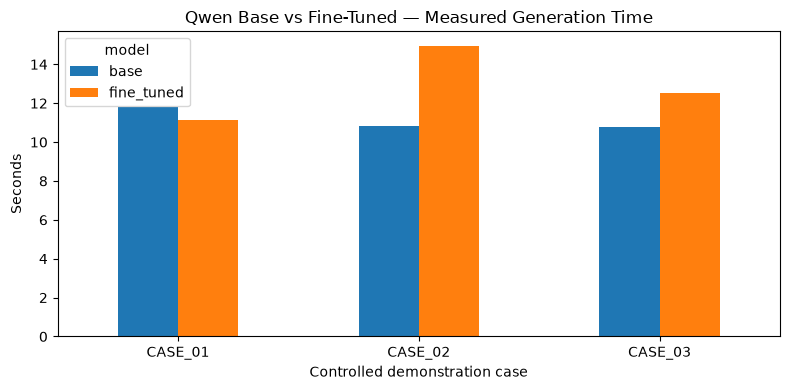

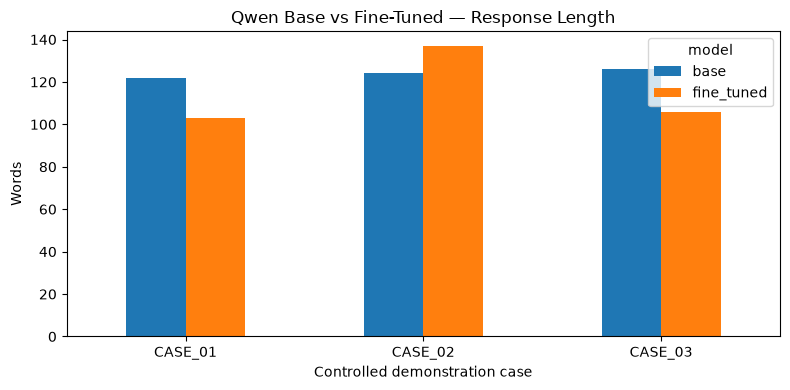


QWEN COMPARISON


,case_id,model,concern,generation_seconds,response_words
0,CASE_01,base,Long Method / High Complexity,11.820,122
1,CASE_01,fine_tuned,Long Method / High Complexity,11.134,103
2,CASE_02,base,Duplicated Logic,10.811,124
3,CASE_02,fine_tuned,Duplicated Logic,14.949,137
4,CASE_03,base,Large Class,10.789,126
5,CASE_03,fine_tuned,Large Class,12.505,106



MODEL SUMMARY


generation_seconds         response_words       
                         mean  median           mean median
model                                                      
base                11.140000  10.811     124.000000  124.0
fine_tuned          12.862667  12.505     115.333333  106.0


Saved: ranking audit, Qwen comparison, 3 graphs, and results report.


In [3]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

root = Path(r"C:\4th Year\Research Work\Implementation Stage\J26-SE-361")
ev = root / "Code Cleanliness" / "evaluation"
base = ev / "results" / "final_evaluation"
graphs = base / "graphs"
graphs.mkdir(parents=True, exist_ok=True)

ranking = pd.read_csv(base / "ranking" / "ranking_independent_review.csv")
llm = pd.read_csv(base / "llm" / "base_vs_finetuned_review.csv")

# 1. Ranking: measure dataset composition, not ranking accuracy.
generated_pattern = (
    r"(?i)(parser|grammaraccess|\.generated\.|"
    r"generated/|generated\\|protobuf|antlr)"
)

ranking["suspected_generated"] = ranking["group_id"].astype(str).str.contains(
    generated_pattern, regex=True, na=False
)

ranking_audit = ranking.groupby("suspected_generated").agg(
    candidate_groups=("group_id", "count"),
    median_analyzer_rank=("analyzer_rank", "median"),
    median_exceedance=("exceedance_score", "median"),
).reset_index()

ranking_audit.to_csv(
    base / "ranking" / "ranking_generated_code_audit.csv", index=False
)

fig, ax = plt.subplots(figsize=(7, 4))
counts = ranking["suspected_generated"].value_counts()
ax.bar(
    ["Suspected generated" if x else "Not flagged" for x in counts.index],
    counts.values
)
ax.set_ylabel("Candidate groups")
ax.set_title("Ranking Sample — Generated-Code Heuristic Audit")
fig.tight_layout()
fig.savefig(graphs / "ranking_generated_code_audit.png", dpi=200)
plt.show()

print("\nRANKING SAMPLE AUDIT")
display(ranking_audit)
print("Independent ranking labels:",
      ranking["independent_priority_rank"].notna().sum(), "/", len(ranking))

# 2. Qwen: compare measured generation latency.
llm["generation_seconds"] = pd.to_numeric(
    llm["generation_seconds"], errors="coerce"
)
llm["response_words"] = llm["response"].fillna("").str.split().str.len()

timing = llm.pivot_table(
    index="case_id",
    columns="model",
    values="generation_seconds",
    aggfunc="first"
)

word_counts = llm.pivot_table(
    index="case_id",
    columns="model",
    values="response_words",
    aggfunc="first"
)

fig, ax = plt.subplots(figsize=(8, 4))
timing.plot(kind="bar", ax=ax)
ax.set_title("Qwen Base vs Fine-Tuned — Measured Generation Time")
ax.set_ylabel("Seconds")
ax.set_xlabel("Controlled demonstration case")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(graphs / "qwen_casewise_generation_time.png", dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
word_counts.plot(kind="bar", ax=ax)
ax.set_title("Qwen Base vs Fine-Tuned — Response Length")
ax.set_ylabel("Words")
ax.set_xlabel("Controlled demonstration case")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(graphs / "qwen_casewise_response_length.png", dpi=200)
plt.show()

comparison = llm[[
    "case_id", "model", "concern",
    "generation_seconds", "response_words"
]].copy()

comparison.to_csv(
    base / "llm" / "qwen_casewise_descriptive_comparison.csv",
    index=False
)

print("\nQWEN COMPARISON")
display(comparison)
print("\nMODEL SUMMARY")
display(llm.groupby("model")[[
    "generation_seconds", "response_words"
]].agg(["mean", "median"]))

# 3. Report actual evidence and unresolved independent validation.
report = f"""# 29F — Ranking and Qwen Experimental Evidence

## Ranking dataset
- Candidate groups: {len(ranking)}
- Suspected generated-code groups: {int(ranking["suspected_generated"].sum())}
- Independent reference ranks available: {int(ranking["independent_priority_rank"].notna().sum())}
- Generated-code detection is filename/identifier heuristic only.
- Spearman, NDCG and Top-k agreement cannot be established without
  independent reference judgments.
- Existing 40-case ranking sample requires representative source review.

## Qwen controlled comparison
- Recorded responses: {len(llm)}
- Distinct cases: {llm["case_id"].nunique()}
- Models: {", ".join(sorted(llm["model"].dropna().astype(str).unique()))}
- Per-case generation-time and response-length comparisons saved.
- All response times come from previously recorded measurements.
- Response length does not measure explanation quality.
- Human correctness, relevance, actionability and grounding ratings
  remain unfilled, so quality superiority is not established.

## Evaluation conclusion
Computational descriptive comparisons are complete on preserved
evidence. Independent ranking accuracy and Qwen explanation-quality
validation remain outstanding.
"""

(ev / "29F_RANKING_QWEN_RESULTS.md").write_text(
    report, encoding="utf-8"
)

print("\nSaved: ranking audit, Qwen comparison, 3 graphs, and results report.")


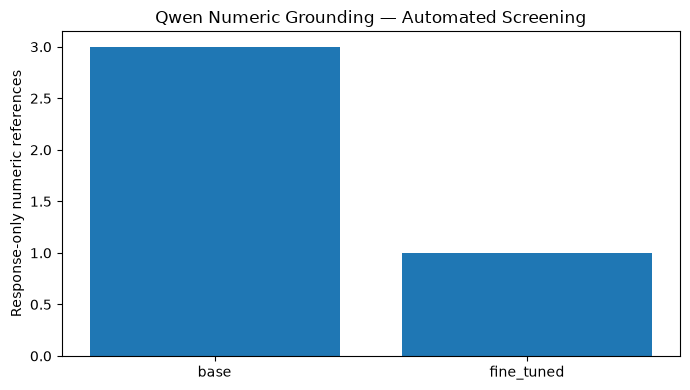

AUTOMATED VALIDATION RESULTS


,test,observations,result,interpretation
0,Ranking score discrimination,40,1 distinct scores; 40 at 1.0,"Descriptive saturation audit, not priority acc..."
1,Ranking score-order consistency,40,0 adjacent score-order inversions,Diagnostic only; ranking may use additional ti...
2,Grouping internal consistency,15,0 contradictory pairs; 0 transitivity violations,"Structural consistency, not grouping accuracy"
3,Qwen numeric-grounding screening,6,4 response-only numeric references,Candidates for unsupported claims; not verifie...



QWEN RESPONSE SCREENING


,case_id,model,generation_seconds,evidence_numbers,response_only_numbers,response_only_number_count
0,CASE_01,base,11.820,,"13, 14",2
1,CASE_01,fine_tuned,11.134,,14,1
2,CASE_02,base,10.811,,,0
3,CASE_02,fine_tuned,14.949,,,0
4,CASE_03,base,10.789,,2000,1
5,CASE_03,fine_tuned,12.505,,,0



Saved: 2 CSV files and 1 graph.
These results do not require external human reviewers.
They are automated diagnostic checks, not external accuracy scores.


In [4]:

from pathlib import Path
from itertools import combinations
import re
import pandas as pd
import matplotlib.pyplot as plt

root = Path(r"C:\4th Year\Research Work\Implementation Stage\J26-SE-361")
base = root / "Code Cleanliness" / "evaluation" / "results" / "final_evaluation"
graphs = base / "graphs"
graphs.mkdir(parents=True, exist_ok=True)

ranking = pd.read_csv(base / "ranking" / "ranking_independent_review.csv")
grouping = pd.read_csv(base / "grouping" / "pilot_pairwise_review.csv")
qwen = pd.read_csv(base / "llm" / "base_vs_finetuned_review.csv")

results = []

# TEST 1: Ranking score discrimination
scores = pd.to_numeric(ranking["exceedance_score"], errors="coerce")
ranks = pd.to_numeric(ranking["analyzer_rank"], errors="coerce")

assert scores.notna().all() and ranks.notna().all()
assert ranks.is_unique

max_score_count = int((scores == 1.0).sum())
unique_scores = int(scores.nunique())

results.append({
    "test": "Ranking score discrimination",
    "observations": len(ranking),
    "result": f"{unique_scores} distinct scores; {max_score_count} at 1.0",
    "interpretation": "Descriptive saturation audit, not priority accuracy"
})

# Check for inversions: a better rank should not have
# a strictly lower score if ranking is score-descending.
ordered = ranking.assign(_rank=ranks, _score=scores).sort_values("_rank")
inversions = int((ordered["_score"].diff().dropna() > 1e-10).sum())

results.append({
    "test": "Ranking score-order consistency",
    "observations": len(ordered),
    "result": f"{inversions} adjacent score-order inversions",
    "interpretation": (
        "Diagnostic only; ranking may use additional tie-breakers"
    )
})

# TEST 2: Grouping internal consistency
# A single pair must not have contradictory assignments.
pair_map = {}
conflicts = 0

for _, row in grouping.iterrows():
    key = tuple(sorted([
        str(row["finding_a_id"]),
        str(row["finding_b_id"])
    ]))
    prediction = int(row["system_same_group"])

    if key in pair_map and pair_map[key] != prediction:
        conflicts += 1
    pair_map[key] = prediction

# Same-group relation should be transitive.
nodes = sorted({
    node for pair in pair_map for node in pair
})
transitivity_violations = 0

for a, b, c in combinations(nodes, 3):
    ab = pair_map.get(tuple(sorted([a, b])))
    ac = pair_map.get(tuple(sorted([a, c])))
    bc = pair_map.get(tuple(sorted([b, c])))

    if None not in (ab, ac, bc):
        if (ab == 1 and ac == 1 and bc == 0) or \
           (ab == 1 and bc == 1 and ac == 0) or \
           (ac == 1 and bc == 1 and ab == 0):
            transitivity_violations += 1

results.append({
    "test": "Grouping internal consistency",
    "observations": len(pair_map),
    "result": (
        f"{conflicts} contradictory pairs; "
        f"{transitivity_violations} transitivity violations"
    ),
    "interpretation": "Structural consistency, not grouping accuracy"
})

# TEST 3: Qwen numeric-grounding screening
# Numbers in the response but absent from the evidence
# are candidates for review, NOT proven hallucinations.
number_pattern = r"(?<![\w.])\d+(?:\.\d+)?(?![\w.])"

screening_rows = []

for _, row in qwen.iterrows():
    evidence_numbers = set(
        re.findall(number_pattern, str(row["evidence"]))
    )
    response_numbers = set(
        re.findall(number_pattern, str(row["response"]))
    )

    new_numbers = sorted(response_numbers - evidence_numbers)

    screening_rows.append({
        "case_id": row["case_id"],
        "model": row["model"],
        "generation_seconds": row["generation_seconds"],
        "evidence_numbers": ", ".join(sorted(evidence_numbers)),
        "response_only_numbers": ", ".join(new_numbers),
        "response_only_number_count": len(new_numbers)
    })

screening = pd.DataFrame(screening_rows)

results.append({
    "test": "Qwen numeric-grounding screening",
    "observations": len(screening),
    "result": (
        f"{int(screening['response_only_number_count'].sum())} "
        "response-only numeric references"
    ),
    "interpretation": (
        "Candidates for unsupported claims; not verified hallucinations"
    )
})

# Save reproducible results.
summary = pd.DataFrame(results)

summary.to_csv(
    base / "ranking" / "automated_validation_summary.csv",
    index=False
)

screening.to_csv(
    base / "llm" / "qwen_numeric_grounding_screen.csv",
    index=False
)

# Create one summary graph for model screening.
fig, ax = plt.subplots(figsize=(7, 4))
models = screening.groupby("model")[
    "response_only_number_count"
].sum()

ax.bar(models.index.astype(str), models.values)
ax.set_ylabel("Response-only numeric references")
ax.set_title("Qwen Numeric Grounding — Automated Screening")
fig.tight_layout()
fig.savefig(
    graphs / "qwen_numeric_grounding_screen.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

print("AUTOMATED VALIDATION RESULTS")
display(summary)

print("\nQWEN RESPONSE SCREENING")
display(screening)

print("\nSaved: 2 CSV files and 1 graph.")
print("These results do not require external human reviewers.")
print("They are automated diagnostic checks, not external accuracy scores.")
